# DeepGuard on NF-ToN-IoT (v3 or v2) – modern NetFlow IoT dataset
Same pipeline as the NSL-KDD+/UNSW-NB15 notebook, plus: **validation split** (model selection on validation, never on test), **PGD attack**, **parameter count + inference latency**.

**Before running**
1. Download NF-ToN-IoT-v3 (or v2) from https://staff.itee.uq.edu.au/marius/NIDS_datasets/ and put ONLY the NF-ToN-IoT csv (or the zip) in Drive: `MyDrive/DeepGuard/data/`
2. Cells 1-3 need NO GPU: you can run them first (even "Connect without GPU") to check the file loads. The sampled data is cached in Drive, so it is read from the huge CSV only once.
3. Cell 2: run once with `QUICK = True` (smoke test). Then `QUICK = False`, GPU runtime, run Cell 2 onward.
Results are saved per seed in Drive (resumable).

In [ ]:
# ===== Cell 1: setup =====
%pip -q install shap imbalanced-learn
import os, glob, json, time, copy, random, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             matthews_corrcoef, roc_auc_score, f1_score, confusion_matrix)
warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/DeepGuard/data"
BASE_OUT = "/content/drive/MyDrive/DeepGuard/results"
print("Data dir:", DATA_DIR)
print(os.listdir(DATA_DIR) if os.path.exists(DATA_DIR) else "DATA_DIR missing!")

Device: cuda
Mounted at /content/drive
Data dir: /content/drive/MyDrive/DeepGuard/data
['KDDTest+.txt', 'KDDTrain+.txt', 'UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv', 'NF-ToN-IoT-v3-sample.csv']


In [ ]:
# ===== Cell 2: configuration =====
QUICK = False          # <-- True = fast smoke test. Set False for the real full run.

SEEDS        = [42, 43, 44]
EPOCHS       = 15
BATCH        = 512
LR           = 2e-3
FED_CLIENTS  = 5
FED_ROUNDS   = 20
FED_BATCH    = 256
ADV_EPS      = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20]
ADV_TRAIN_EPS, ADV_FT_EPOCHS, ADV_FT_LR = 0.05, 2, 1e-3
PGD_EPS, PGD_STEPS, PGD_N = [0.0, 0.05, 0.10], 10, 10000     # PGD on first 10k test flows (it is 10x costlier)
GAN_ITERS    = 3000
AUG_TARGET   = 8000        # classes with fewer train samples than this are "minority" and raised to this size
NF_CAP       = 30000       # max flows kept per class when sampling the huge CSV (rare classes are kept in full)
TRAIN_CAP    = None
RUN_SHAP     =  True
NF_FILE      = None        # optional: full path of the csv, e.g. '/content/drive/MyDrive/DeepGuard/data/NF-ToN-IoT-v3.csv'
if QUICK:
    SEEDS, EPOCHS, FED_ROUNDS, GAN_ITERS = [42,43], 2, 3, 300
    TRAIN_CAP, AUG_TARGET, NF_CAP = 20000, 1500, 5000

OUT = os.path.join(BASE_OUT, "nf_ton_iot", "quick" if QUICK else "full")
os.makedirs(OUT, exist_ok=True)
print("QUICK =", QUICK, "| seeds:", SEEDS, "| results ->", OUT)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

QUICK = False | seeds: [42, 43, 44] | results -> /content/drive/MyDrive/DeepGuard/results/nf_ton_iot/full


In [ ]:
# ===== Cell 3: locate, sample and preprocess NF-ToN-IoT-v2 =====
import shutil, zipfile, re
LOCAL_CSV = "/content/nf_local.csv"
DROP_COLS = {"ipv4_src_addr", "ipv4_dst_addr"}          # IP addresses are identifiers, not behaviour -> dropped

def locate_nf():
    if NF_FILE: return NF_FILE
    def hit(n): n = n.lower(); return "ton" in n and ("v3" in n or "v2" in n)
    csvs = [p for p in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True) if hit(os.path.basename(p))]
    if not csvs:   # look inside zip files, extract ONLY the NF-ToN-IoT csv (a zip may hold several datasets)
        for z in glob.glob(os.path.join(DATA_DIR, "**", "*.zip"), recursive=True):
            zf = zipfile.ZipFile(z)
            for m in zf.namelist():
                if m.lower().endswith(".csv") and hit(os.path.basename(m)):
                    print("Extracting", m, "from", z); csvs.append(zf.extract(m, "/content/nf_unzip"))
    if not csvs: raise FileNotFoundError(f"No NF-ToN-IoT csv/zip found in {DATA_DIR}. Set NF_FILE in Cell 2.")
    return max(csvs, key=os.path.getsize)

TIME_TOKENS = {"start", "end", "timestamp", "time"}
def is_time_col(c): return any(t in TIME_TOKENS for t in re.split(r"[^a-z0-9]+", c.lower()))

def load_nf():
    path = locate_nf(); ver = "v3" if "v3" in os.path.basename(path).lower() else "v2"
    name = f"NF-ToN-IoT-{ver}"
    sample_pkl = os.path.join(BASE_OUT, "nf_ton_iot", f"sample_{ver}_cap{NF_CAP}.pkl")
    print("Source file:", path, f"({os.path.getsize(path)/1e9:.2f} GB)")
    if os.path.exists(sample_pkl):
        df, ATT = pd.read_pickle(sample_pkl); print("Loaded cached sample:", sample_pkl)
    else:
        if not os.path.exists(LOCAL_CSV) or os.path.getsize(LOCAL_CSV) != os.path.getsize(path):
            shutil.copyfile(path, LOCAL_CSV)                 # local disk is much faster than Drive for 2 passes
        hdr = [c.strip() for c in pd.read_csv(LOCAL_CSV, nrows=0).columns]
        low = {c.lower(): c for c in hdr}
        ATT = low.get("attack")
        assert ATT is not None, f"No 'Attack' column. Columns: {hdr}"
        print(f"{len(hdr)} columns:", hdr)
        cnt = {}
        for ch in pd.read_csv(LOCAL_CSV, usecols=lambda c: c.strip() == ATT, chunksize=2_000_000):
            for k, v in ch[ch.columns[0]].astype(str).str.strip().value_counts().items(): cnt[k] = cnt.get(k, 0) + int(v)
        print("Full-dataset class counts:", cnt, "| total:", sum(cnt.values()))
        frac = {k: min(1.0, NF_CAP / v) for k, v in cnt.items()}
        rng = np.random.RandomState(0); parts = []
        for ch in pd.read_csv(LOCAL_CSV, chunksize=1_000_000):
            ch.columns = [c.strip() for c in ch.columns]
            p = ch[ATT].astype(str).str.strip().map(frac).fillna(0).values
            parts.append(ch[rng.rand(len(ch)) < p])
        df = pd.concat(parts, ignore_index=True); df[ATT] = df[ATT].astype(str).str.strip()
        os.makedirs(os.path.dirname(sample_pkl), exist_ok=True); pd.to_pickle((df, ATT), sample_pkl)
        print("Sampled", len(df), "rows -> cached", sample_pkl)

    lab_cols = [c for c in df.columns if c.lower() in ("label", "attack")]
    dropped_time = [c for c in df.columns if is_time_col(c)]      # timestamps would let the model "cheat" on time -> dropped
    feat_cols = [c for c in df.columns if c not in lab_cols and c.lower() not in DROP_COLS and c not in dropped_time]
    print("Dropped timestamp columns:", dropped_time, "| IP columns dropped:", [c for c in df.columns if c.lower() in DROP_COLS])
    n0 = len(df)
    df = df.drop_duplicates(subset=feat_cols + [ATT]).reset_index(drop=True)   # duplicate flows would leak across splits
    print(f"Removed {n0-len(df)} duplicate flows -> {len(df)} left")
    Xdf = df[feat_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
    Xall = Xdf.values.astype(np.float64)
    for j in range(Xall.shape[1]):                          # heavy-tailed counts/bytes -> log1p (non-negative cols only)
        if Xall[:, j].min() >= 0: Xall[:, j] = np.log1p(Xall[:, j])
    classes = sorted(df[ATT].unique().tolist()); c2i = {c: i for i, c in enumerate(classes)}
    y = df[ATT].map(c2i).values.astype(np.int64)

    # stratified 70 / 10 / 20 split (train / validation / test), fixed so every seed sees the same split
    idx = np.arange(len(y))
    i_tr, i_te = train_test_split(idx, test_size=0.20, stratify=y, random_state=0)
    i_tr, i_va = train_test_split(i_tr, test_size=0.125, stratify=y[i_tr], random_state=0)
    if TRAIN_CAP and len(i_tr) > TRAIN_CAP:
        i_tr, _ = train_test_split(i_tr, train_size=TRAIN_CAP, stratify=y[i_tr], random_state=0)
    sc = StandardScaler().fit(Xall[i_tr])                   # fit on train only
    f = lambda i: sc.transform(Xall[i]).astype(np.float32)
    D = dict(Xtr=f(i_tr), ytr=y[i_tr], Xva=f(i_va), yva=y[i_va], Xte=f(i_te), yte=y[i_te], classes=classes, features=feat_cols)
    cnt_tr = np.bincount(D["ytr"], minlength=len(classes))
    minority = [classes[i] for i in range(len(classes)) if cnt_tr[i] < AUG_TARGET]
    if not minority: minority = [classes[i] for i in np.argsort(cnt_tr)[:2]]
    D["minority"] = minority
    print(f"{name}: train {D['Xtr'].shape}, val {D['Xva'].shape}, test {D['Xte'].shape}, features={len(feat_cols)}")
    for nm, yy in [("train", D["ytr"]), ("val", D["yva"]), ("test", D["yte"])]:
        print(f"  {nm:5s} class counts:", dict(zip(classes, np.bincount(yy, minlength=len(classes)).tolist())))
    print("  minority classes (augmented):", minority)
    return D, name

D_nf, NF_NAME = load_nf()
DATA = {NF_NAME: D_nf}

Source file: /content/drive/MyDrive/DeepGuard/data/NF-ToN-IoT-v3-sample.csv (0.05 GB)
Loaded cached sample: /content/drive/MyDrive/DeepGuard/results/nf_ton_iot/sample_v3_cap30000.pkl
Dropped timestamp columns: ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS'] | IP columns dropped: ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR']
Removed 19415 duplicate flows -> 230343 left
NF-ToN-IoT-v3: train (161239, 49), val (23035, 49), test (46069, 49), features=49
  train class counts: {'Backdoor': 19224, 'Benign': 18335, 'ddos': 17414, 'dos': 20933, 'injection': 20934, 'mitm': 3539, 'password': 20857, 'ransomware': 2471, 'scanning': 16540, 'xss': 20992}
  val   class counts: {'Backdoor': 2746, 'Benign': 2619, 'ddos': 2488, 'dos': 2991, 'injection': 2991, 'mitm': 505, 'password': 2980, 'ransomware': 353, 'scanning': 2363, 'xss': 2999}
  test  class counts: {'Backdoor': 5492, 'Benign': 5239, 'ddos': 4976, 'dos': 5981, 'injection': 5981, 'mitm': 1011, 'password': 5959, 'ransomware': 706, 'scanning': 4726, 'xs

In [ ]:
# ===== Cell 4: model, metrics, training utilities =====
class DeepGuard(nn.Module):
    """1-D CNN (16/32/64, dilation 1/2/2, residual) -> BiLSTM(24x2) -> 4-head MHSA + LN -> mean pool -> FC(48-64-C)."""
    def __init__(self, n_classes):
        super().__init__()
        self.c1 = nn.Conv1d(1, 16, 3, padding=1, dilation=1)
        self.c2 = nn.Conv1d(16, 32, 3, padding=2, dilation=2); self.b2 = nn.BatchNorm1d(32)
        self.c3 = nn.Conv1d(32, 64, 3, padding=2, dilation=2); self.b3 = nn.BatchNorm1d(64)
        self.proj = nn.Conv1d(16, 64, 1)
        self.lstm = nn.LSTM(64, 24, batch_first=True, bidirectional=True)
        self.attn = nn.MultiheadAttention(48, 4, batch_first=True)
        self.ln = nn.LayerNorm(48)
        self.fc1 = nn.Linear(48, 64); self.drop = nn.Dropout(0.3); self.fc2 = nn.Linear(64, n_classes)
    def forward(self, x):
        x = x.unsqueeze(1)
        h1 = F.relu(self.c1(x))
        h2 = F.relu(self.b2(self.c2(h1)))
        h3 = F.relu(self.b3(self.c3(h2) + self.proj(h1)))
        h, _ = self.lstm(h3.transpose(1, 2))
        a, _ = self.attn(h, h, h)
        z = self.ln(h + a).mean(1)
        return self.fc2(self.drop(F.relu(self.fc1(z))))

print("Trainable parameters (C=5):", sum(p.numel() for p in DeepGuard(5).parameters() if p.requires_grad))

def class_weights(y, C):   # inverse-log-frequency weights (Sec 4.5), normalised to mean 1
    cnt = np.bincount(y, minlength=C).astype(float)
    w = 1.0 / np.log(1.1 + cnt)
    return torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)

def batches(X, y, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], y[j]

def train_model(model, X, y, epochs, lr=LR, w=None, bs=BATCH, tag="", verbose=True, val=None):
    """If val=(X_val_tensor, y_val_numpy) is given, the epoch with best validation macro-F1 is kept (never uses test)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr); best, best_state = -1.0, None
    for ep in range(epochs):
        model.train(); tot = 0.0; n = 0
        for xb, yb in batches(X, y, bs):
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb, weight=w)
            loss.backward(); opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        msg = f"    [{tag}] epoch {ep+1}/{epochs} loss={tot/n:.4f}"
        if val is not None:
            pv = predict_proba(model, val[0]).argmax(1)
            fv = f1_score(val[1], pv, average="macro", zero_division=0)
            if fv > best: best, best_state = fv, {k: v.detach().clone() for k, v in model.state_dict().items()}
            msg += f" val-macroF1={fv:.4f}"
        if verbose and (ep == 0 or (ep + 1) % 5 == 0 or ep == epochs - 1): print(msg)
    if best_state is not None: model.load_state_dict(best_state)
    return model

@torch.no_grad()
def predict_proba(model, X, bs=4096):
    model.eval()
    return torch.cat([F.softmax(model(X[i:i + bs]), 1) for i in range(0, len(X), bs)]).cpu().numpy()

def macro_auc(y, S, C):
    aucs = []
    for c in range(C):
        yb = (y == c).astype(int)
        if 0 < yb.sum() < len(yb):
            aucs.append(roc_auc_score(yb, S[:, c]))
    return float(np.mean(aucs))

def evaluate(y, pred, S, C):
    L = list(range(C))
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=L, average="macro", zero_division=0)
    pcp, pcr, pcf, _ = precision_recall_fscore_support(y, pred, labels=L, average=None, zero_division=0)
    return dict(accuracy=float(accuracy_score(y, pred)), macro_precision=float(p), macro_recall=float(r),
                macro_f1=float(f), mcc=float(matthews_corrcoef(y, pred)), macro_auc=macro_auc(y, S, C),
                per_class_precision=pcp.tolist(), per_class_recall=pcr.tolist(), per_class_f1=pcf.tolist())

def latency_ms(model, X, n=5000, bs=1000):
    model.eval(); X = X[:n]
    with torch.no_grad():
        model(X[:bs])
        if DEVICE == "cuda": torch.cuda.synchronize()
        t = time.time()
        for i in range(0, len(X), bs): model(X[i:i + bs])
        if DEVICE == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / len(X) * 1000.0

Trainable parameters (C=5): 39365


In [ ]:
# ===== Cell 5: cWGAN-GP + SMOTE augmentation =====
ZD, ED = 16, 8
class Gen(nn.Module):
    def __init__(self, nf, nc):
        super().__init__()
        self.emb = nn.Embedding(nc, ED)
        self.net = nn.Sequential(nn.Linear(ZD + ED, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, nf))
    def forward(self, z, c): return self.net(torch.cat([z, self.emb(c)], 1))

class Critic(nn.Module):
    def __init__(self, nf, nc):
        super().__init__()
        self.emb = nn.Embedding(nc, ED)
        self.net = nn.Sequential(nn.Linear(nf + ED, 128), nn.LeakyReLU(0.2), nn.Linear(128, 128), nn.LeakyReLU(0.2), nn.Linear(128, 1))
    def forward(self, x, c): return self.net(torch.cat([x, self.emb(c)], 1))

def gradient_penalty(D, real, fake, c):
    a = torch.rand(len(real), 1, device=DEVICE)
    xh = (a * real + (1 - a) * fake).requires_grad_(True)
    g = torch.autograd.grad(D(xh, c).sum(), xh, create_graph=True)[0]
    return ((g.norm(2, dim=1) - 1) ** 2).mean()

def train_cwgan(Xm, ym, nf, nc, min_ids, iters, bs=64, lam=10.0, n_critic=3):
    G, D = Gen(nf, nc).to(DEVICE), Critic(nf, nc).to(DEVICE)
    oG = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))
    oD = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.9))
    pools = {c: torch.where(ym == c)[0] for c in min_ids}
    per = max(1, bs // len(min_ids))
    def sample_real():   # class-balanced mini-batch so rare classes are learnt too
        idx, cl = [], []
        for c, pool in pools.items():
            idx.append(pool[torch.randint(len(pool), (per,), device=DEVICE)]); cl.append(torch.full((per,), c, device=DEVICE))
        return Xm[torch.cat(idx)], torch.cat(cl).long()
    for it in range(iters):
        for _ in range(n_critic):
            real, c = sample_real()
            fake = G(torch.randn(len(real), ZD, device=DEVICE), c).detach()
            lossD = D(fake, c).mean() - D(real, c).mean() + lam * gradient_penalty(D, real, fake, c)
            oD.zero_grad(); lossD.backward(); oD.step()
        real, c = sample_real()
        lossG = -D(G(torch.randn(len(real), ZD, device=DEVICE), c), c).mean()
        oG.zero_grad(); lossG.backward(); oG.step()
        if it % 1000 == 0 or it == iters - 1:
            print(f"    [cWGAN-GP] it {it}: critic={lossD.item():.3f} gen={lossG.item():.3f}")
    return G

def gan_aug(X, y, min_ids, C, seed):
    set_seed(seed)
    m = np.isin(y, min_ids)
    Xm, ym = torch.tensor(X[m], device=DEVICE), torch.tensor(y[m], device=DEVICE)
    G = train_cwgan(Xm, ym, X.shape[1], C, min_ids, GAN_ITERS)
    cnt = np.bincount(y, minlength=C); Xn, yn = [X], [y]
    for c in min_ids:
        need = int(AUG_TARGET - cnt[c])
        if need > 0:
            with torch.no_grad():
                g = G(torch.randn(need, ZD, device=DEVICE), torch.full((need,), int(c), device=DEVICE, dtype=torch.long))
            Xn.append(g.cpu().numpy().astype(np.float32)); yn.append(np.full(need, c, dtype=np.int64))
    return np.concatenate(Xn), np.concatenate(yn)

def smote_aug(X, y, min_ids, C, seed):
    from imblearn.over_sampling import SMOTE
    cnt = np.bincount(y, minlength=C)
    strat = {int(c): AUG_TARGET for c in min_ids if cnt[c] < AUG_TARGET}
    if not strat: return X, y
    k = max(1, min(5, int(min(cnt[c] for c in strat)) - 1))
    Xr, yr = SMOTE(sampling_strategy=strat, k_neighbors=k, random_state=seed).fit_resample(X, y)
    return Xr.astype(np.float32), yr.astype(np.int64)

In [ ]:
# ===== Cell 6: FGSM adversarial evaluation / fine-tuning + FedAvg =====
def fgsm(model, x, y, eps):
    x = x.clone().detach().requires_grad_(True)
    with torch.backends.cudnn.flags(enabled=False):   # cuDNN RNN backward is not allowed in eval mode
        loss = F.cross_entropy(model(x), y)
        g, = torch.autograd.grad(loss, x)
    return (x + eps * g.sign()).detach()

def pgd(model, x, y, eps, steps=PGD_STEPS):
    alpha = 2.5 * eps / steps
    xa = x.clone().detach() + torch.empty_like(x).uniform_(-eps, eps)
    for _ in range(steps):
        xa.requires_grad_(True)
        with torch.backends.cudnn.flags(enabled=False):
            loss = F.cross_entropy(model(xa), y)
            g, = torch.autograd.grad(loss, xa)
        xa = xa.detach() + alpha * g.sign()
        xa = torch.min(torch.max(xa, x - eps), x + eps).detach()
    return xa

def adv_eval(model, X, y_t, y_np, C, eps_list, attack="fgsm", n=None, bs=2048):
    if n: X, y_t, y_np = X[:n], y_t[:n], y_np[:n]
    model.eval(); res = {}
    for eps in eps_list:
        preds = []
        for i in range(0, len(X), bs):
            xb, yb = X[i:i + bs], y_t[i:i + bs]
            if eps > 0: xb = fgsm(model, xb, yb, eps) if attack == "fgsm" else pgd(model, xb, yb, eps)
            with torch.no_grad(): preds.append(model(xb).argmax(1))
        p = torch.cat(preds).cpu().numpy()
        res[eps] = (float(accuracy_score(y_np, p)), float(f1_score(y_np, p, average="macro", labels=list(range(C)), zero_division=0)))
    return res

def adv_finetune(model, X, y, w, epochs=ADV_FT_EPOCHS, eps=ADV_TRAIN_EPS, lr=ADV_FT_LR):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        for xb, yb in batches(X, y, BATCH):
            xa = fgsm(model, xb, yb, eps)
            opt.zero_grad()
            loss = 0.5 * F.cross_entropy(model(xb), yb, weight=w) + 0.5 * F.cross_entropy(model(xa), yb, weight=w)
            loss.backward(); opt.step()
        print(f"    [adv-FT] epoch {ep+1}/{epochs} done")
    return model

def make_partition(y, K, mode, seed):
    rng = np.random.RandomState(seed)
    if mode == "iid":
        return np.array_split(rng.permutation(len(y)), K)
    order = rng.permutation(len(y)); order = order[np.argsort(y[order], kind="stable")]   # sort by label
    shards = np.array_split(order, 2 * K); perm = rng.permutation(2 * K)                    # 2 shards / client
    return [np.concatenate([shards[perm[2 * k]], shards[perm[2 * k + 1]]]) for k in range(K)]

def fedavg(X, y_t, y_np, Xte, yte, C, w, mode, seed, rounds=FED_ROUNDS, K=FED_CLIENTS):
    set_seed(seed)
    parts = make_partition(y_np, K, mode, seed)
    print(f"    [FedAvg-{mode}] classes/client:", [len(np.unique(y_np[p])) for p in parts])
    gm = DeepGuard(C).to(DEVICE); sizes = np.array([len(p) for p in parts], dtype=float); hist = []
    for r in range(rounds):
        states = []
        for p in parts:
            local = copy.deepcopy(gm); idx = torch.tensor(p, device=DEVICE)
            train_model(local, X[idx], y_t[idx], 1, w=w, bs=FED_BATCH, verbose=False)
            states.append(local.state_dict())
        avg = {}
        for key in states[0]:
            if states[0][key].dtype.is_floating_point:
                avg[key] = sum(st[key] * (n / sizes.sum()) for st, n in zip(states, sizes))
            else:
                avg[key] = states[0][key]
        gm.load_state_dict(avg)
        pr = predict_proba(gm, Xte).argmax(1)
        hist.append((float(accuracy_score(yte, pr)), float(f1_score(yte, pr, average="macro", labels=list(range(C)), zero_division=0))))
        if r == 0 or (r + 1) % 5 == 0 or r == rounds - 1:
            print(f"    [FedAvg-{mode}] round {r+1}/{rounds} acc={hist[-1][0]:.4f} mF1={hist[-1][1]:.4f}")
    return gm, hist

In [ ]:
# ===== Cell 7: one full experiment (seed) =====
def run_one(name, D, seed):
    C, classes = len(D["classes"]), D["classes"]
    Xtr, ytr, Xva, yva, Xte, yte = D["Xtr"], D["ytr"], D["Xva"], D["yva"], D["Xte"], D["yte"]
    min_ids = [classes.index(c) for c in D["minority"]]
    Xte_t, yte_t = torch.tensor(Xte, device=DEVICE), torch.tensor(yte, device=DEVICE)
    Xva_t = torch.tensor(Xva, device=DEVICE)
    Xtr_t, ytr_t = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    out = {"main": [], "adv": [], "fed": [], "preds": {}, "meta": {}}

    def log(method, S, keep=False):
        pred = S.argmax(1); m = evaluate(yte, pred, S, C)
        out["main"].append({"dataset": name, "seed": seed, "method": method, **m})
        if keep: out["preds"][method] = pred.astype(int).tolist()
        print(f"  {method:26s} acc={m['accuracy']:.4f}  macroF1={m['macro_f1']:.4f}  AUC={m['macro_auc']:.4f}")

    def fit_dg(Xa, ya, tag):
        set_seed(seed)
        Xt, yt = torch.tensor(Xa, device=DEVICE), torch.tensor(ya, device=DEVICE)
        m = DeepGuard(C).to(DEVICE); w = class_weights(ya, C)
        train_model(m, Xt, yt, EPOCHS, w=w, tag=tag, val=(Xva_t, yva))
        return m, w, Xt, yt

    def adv_rows(model, mdl):
        for atk, eps_list, n in [("fgsm", ADV_EPS, None), ("pgd", PGD_EPS, PGD_N)]:
            for eps, (a, f1) in adv_eval(model, Xte_t, yte_t, yte, C, eps_list, attack=atk, n=n).items():
                out["adv"].append(dict(dataset=name, seed=seed, model=mdl, attack=atk, eps=eps, accuracy=a, macro_f1=f1))

    # ---- classical baselines ----
    set_seed(seed)
    rf = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=seed).fit(Xtr, ytr)
    log("Random Forest", rf.predict_proba(Xte), keep=True)
    lr = LogisticRegression(max_iter=300).fit(Xtr, ytr); log("Logistic Regression", lr.predict_proba(Xte))
    svm = LinearSVC(max_iter=2000, random_state=seed).fit(Xtr, ytr); log("Linear SVM", svm.decision_function(Xte))

    # ---- ablation arms ----
    m0, _, _, _ = fit_dg(Xtr, ytr, "no-aug"); log("DeepGuard (no aug)", predict_proba(m0, Xte_t)); del m0
    Xs, ys = smote_aug(Xtr, ytr, min_ids, C, seed)
    m1, _, _, _ = fit_dg(Xs, ys, "SMOTE"); log("DeepGuard + SMOTE", predict_proba(m1, Xte_t)); del m1
    Xg, yg = gan_aug(Xtr, ytr, min_ids, C, seed)
    mg, wg, Xgt, ygt = fit_dg(Xg, yg, "cWGAN-GP")
    log("DeepGuard (cWGAN-GP)", predict_proba(mg, Xte_t), keep=True)
    torch.save(mg.state_dict(), os.path.join(OUT, f"{name}_seed{seed}_main.pt"))
    out["meta"] = {"params": int(sum(p.numel() for p in mg.parameters())), "latency_ms_per_flow": latency_ms(mg, Xte_t)}
    print("  model:", out["meta"])

    # ---- adversarial robustness (FGSM full test set, PGD on first PGD_N flows) ----
    adv_rows(mg, "standard")
    mf = adv_finetune(copy.deepcopy(mg), Xgt, ygt, wg)
    log("DeepGuard + adv. FT", predict_proba(mf, Xte_t))
    adv_rows(mf, "adv_finetuned")
    del mf, mg

    # ---- federated learning ----
    wfull = class_weights(ytr, C)
    for mode, label in [("noniid", "FedAvg (non-IID)"), ("iid", "FedAvg (IID)")]:
        gm, hist = fedavg(Xtr_t, ytr_t, ytr, Xte_t, yte, C, wfull, mode, seed)
        for r, (a, f1) in enumerate(hist, 1):
            out["fed"].append(dict(dataset=name, seed=seed, partition=mode, round=r, accuracy=a, macro_f1=f1))
        log(label, predict_proba(gm, Xte_t)); del gm
    torch.cuda.empty_cache()
    return out

In [ ]:
# ===== Cell 8: RUN EVERYTHING (resumable) =====
for name, D in DATA.items():
    for seed in SEEDS:
        path = os.path.join(OUT, f"{name}_seed{seed}.json")
        if os.path.exists(path):
            print(f"skip {name} seed {seed} (already done)"); continue
        print(f"\n===== {name} | seed {seed} =====")
        t0 = time.time()
        res = run_one(name, D, seed)
        json.dump(res, open(path, "w"))
        print(f"  finished in {(time.time()-t0)/60:.1f} min -> {path}")
print("\nALL DONE")

skip NF-ToN-IoT-v3 seed 42 (already done)
skip NF-ToN-IoT-v3 seed 43 (already done)
skip NF-ToN-IoT-v3 seed 44 (already done)

ALL DONE


In [ ]:
# ===== Cell 9: aggregate -> mean +- std tables (saved as CSV in Drive) =====
main, adv, fed = [], [], []
for f in sorted(glob.glob(os.path.join(OUT, "*_seed*.json"))):
    d = json.load(open(f)); main += d["main"]; adv += d["adv"]; fed += d["fed"]
df, dadv, dfed = pd.DataFrame(main), pd.DataFrame(adv), pd.DataFrame(fed)
METRICS = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "mcc", "macro_auc"]
ORDER = ["Random Forest", "Logistic Regression", "Linear SVM", "DeepGuard (no aug)", "DeepGuard + SMOTE",
         "DeepGuard (cWGAN-GP)", "DeepGuard + adv. FT", "FedAvg (non-IID)", "FedAvg (IID)"]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)

def pm(s): return f"{s.mean():.3f} ± {s.std(ddof=1):.3f}" if len(s) > 1 else f"{s.mean():.3f}"

# Table A: main comparison
tabA = df.groupby(["dataset", "method"])[METRICS].agg(pm).reset_index()
tabA["o"] = tabA["method"].map({m: i for i, m in enumerate(ORDER)}); tabA = tabA.sort_values(["dataset", "o"]).drop(columns="o")
print("=== Table A: all methods (mean ± std over seeds) ==="); display(tabA); tabA.to_csv(os.path.join(OUT, "tableA_main.csv"), index=False)

# Table B: ablation incl. minority-class recall
rows = []
for ds in df.dataset.unique():
    cl = DATA[ds]["classes"]
    for meth in ["DeepGuard (no aug)", "DeepGuard + SMOTE", "DeepGuard (cWGAN-GP)"]:
        sub = df[(df.dataset == ds) & (df.method == meth)]
        r = {"dataset": ds, "method": meth, "macro_f1": pm(sub.macro_f1), "accuracy": pm(sub.accuracy)}
        for mc in DATA[ds]["minority"]:
            i = cl.index(mc); r[f"recall_{mc}"] = pm(sub.per_class_recall.apply(lambda l: l[i]))
        rows.append(r)
tabB = pd.DataFrame(rows); print("\n=== Table B: augmentation ablation ==="); display(tabB); tabB.to_csv(os.path.join(OUT, "tableB_ablation.csv"), index=False)

# Table C: adversarial robustness
tabC = dadv.groupby(["dataset", "attack", "model", "eps"])["accuracy"].agg(pm).unstack("eps")
print("\n=== Table C: FGSM / PGD accuracy vs eps ==="); display(tabC); tabC.to_csv(os.path.join(OUT, "tableC_adversarial.csv"))

# Table D: federated final-round
tabD = tabA[tabA.method.isin(["DeepGuard (cWGAN-GP)", "DeepGuard (no aug)", "FedAvg (non-IID)", "FedAvg (IID)"])]
print("\n=== Table D: centralised vs federated ==="); display(tabD); tabD.to_csv(os.path.join(OUT, "tableD_federated.csv"), index=False)

# Table E: model size and speed
meta = [dict(seed=int(os.path.basename(f).split("_seed")[1].split(".")[0]), **json.load(open(f))["meta"])
        for f in sorted(glob.glob(os.path.join(OUT, "*_seed*.json")))]
tabE = pd.DataFrame(meta); print("\n=== Table E: parameters and inference latency ==="); display(tabE)
tabE.to_csv(os.path.join(OUT, "tableE_meta.csv"), index=False)

=== Table A: all methods (mean ± std over seeds) ===


,dataset,method,accuracy,macro_precision,macro_recall,macro_f1,mcc,macro_auc
8,NF-ToN-IoT-v3,Random Forest,0.930 ± 0.000,0.934 ± 0.000,0.936 ± 0.000,0.934 ± 0.000,0.921 ± 0.000,0.996 ± 0.000
7,NF-ToN-IoT-v3,Logistic Regression,0.875 ± 0.000,0.879 ± 0.000,0.862 ± 0.000,0.862 ± 0.000,0.861 ± 0.000,0.987 ± 0.000
6,NF-ToN-IoT-v3,Linear SVM,0.854 ± 0.000,0.861 ± 0.000,0.841 ± 0.000,0.844 ± 0.000,0.837 ± 0.000,0.980 ± 0.000
1,NF-ToN-IoT-v3,DeepGuard (no aug),0.923 ± 0.001,0.927 ± 0.003,0.924 ± 0.001,0.925 ± 0.001,0.913 ± 0.001,0.995 ± 0.000
2,NF-ToN-IoT-v3,DeepGuard + SMOTE,0.923 ± 0.000,0.921 ± 0.001,0.929 ± 0.001,0.924 ± 0.000,0.913 ± 0.000,0.995 ± 0.000
0,NF-ToN-IoT-v3,DeepGuard (cWGAN-GP),0.923 ± 0.001,0.928 ± 0.002,0.923 ± 0.000,0.925 ± 0.001,0.914 ± 0.001,0.995 ± 0.000
3,NF-ToN-IoT-v3,DeepGuard + adv. FT,0.924 ± 0.000,0.927 ± 0.001,0.925 ± 0.001,0.925 ± 0.000,0.914 ± 0.000,0.995 ± 0.000
5,NF-ToN-IoT-v3,FedAvg (non-IID),0.769 ± 0.019,0.811 ± 0.056,0.690 ± 0.052,0.678 ± 0.066,0.748 ± 0.019,0.978 ± 0.007
4,NF-ToN-IoT-v3,FedAvg (IID),0.920 ± 0.001,0.921 ± 0.002,0.922 ± 0.003,0.920 ± 0.001,0.910 ± 0.001,0.995 ± 0.000



=== Table B: augmentation ablation ===


,dataset,method,macro_f1,accuracy,recall_mitm,recall_ransomware
0,NF-ToN-IoT-v3,DeepGuard (no aug),0.925 ± 0.001,0.923 ± 0.001,0.887 ± 0.014,0.993 ± 0.002
1,NF-ToN-IoT-v3,DeepGuard + SMOTE,0.924 ± 0.000,0.923 ± 0.000,0.936 ± 0.009,0.996 ± 0.002
2,NF-ToN-IoT-v3,DeepGuard (cWGAN-GP),0.925 ± 0.001,0.923 ± 0.001,0.875 ± 0.009,0.990 ± 0.004



=== Table C: FGSM / PGD accuracy vs eps ===


eps                                          0.00           0.01           0.02           0.05           0.10           0.15           0.20
dataset       attack model                                                                                                                 
NF-ToN-IoT-v3 fgsm   adv_finetuned  0.924 ± 0.000  0.921 ± 0.000  0.919 ± 0.001  0.910 ± 0.001  0.850 ± 0.021  0.715 ± 0.038  0.544 ± 0.032
                     standard       0.923 ± 0.001  0.916 ± 0.001  0.904 ± 0.006  0.822 ± 0.012  0.688 ± 0.029  0.558 ± 0.029  0.456 ± 0.029
              pgd    adv_finetuned  0.923 ± 0.001            NaN            NaN  0.902 ± 0.002  0.684 ± 0.022            NaN            NaN
                     standard       0.922 ± 0.002            NaN            NaN  0.791 ± 0.021  0.500 ± 0.009            NaN            NaN


=== Table D: centralised vs federated ===


,dataset,method,accuracy,macro_precision,macro_recall,macro_f1,mcc,macro_auc
1,NF-ToN-IoT-v3,DeepGuard (no aug),0.923 ± 0.001,0.927 ± 0.003,0.924 ± 0.001,0.925 ± 0.001,0.913 ± 0.001,0.995 ± 0.000
0,NF-ToN-IoT-v3,DeepGuard (cWGAN-GP),0.923 ± 0.001,0.928 ± 0.002,0.923 ± 0.000,0.925 ± 0.001,0.914 ± 0.001,0.995 ± 0.000
5,NF-ToN-IoT-v3,FedAvg (non-IID),0.769 ± 0.019,0.811 ± 0.056,0.690 ± 0.052,0.678 ± 0.066,0.748 ± 0.019,0.978 ± 0.007
4,NF-ToN-IoT-v3,FedAvg (IID),0.920 ± 0.001,0.921 ± 0.002,0.922 ± 0.003,0.920 ± 0.001,0.910 ± 0.001,0.995 ± 0.000



=== Table E: parameters and inference latency ===


,seed,params,latency_ms_per_flow
0,42,39690,0.005964
1,43,39690,0.005995
2,44,39690,0.006098


In [ ]:
# ===== Cell 10: statistical tests (the gap flagged in your paper's Section 18) =====
from scipy import stats
print("--- Paired t-test over seeds on macro-F1 (needs >= 3 seeds) ---")
for ds in df.dataset.unique():
    piv = df[df.dataset == ds].pivot(index="seed", columns="method", values="macro_f1")
    for a, b in [("DeepGuard (cWGAN-GP)", "Random Forest"), ("DeepGuard (cWGAN-GP)", "DeepGuard (no aug)"),
                 ("DeepGuard (cWGAN-GP)", "DeepGuard + SMOTE")]:
        if len(piv) >= 3:
            t, p = stats.ttest_rel(piv[a], piv[b])
            print(f"{ds:10s} {a} vs {b}: diff={piv[a].mean()-piv[b].mean():+.4f}  p={p:.4f}")

print("\n--- McNemar test + bootstrap 95% CI (first seed, DeepGuard vs Random Forest) ---")
s0 = SEEDS[0]
for ds in df.dataset.unique():
    d = json.load(open(os.path.join(OUT, f"{ds}_seed{s0}.json")))
    y = DATA[ds]["yte"]; C = len(DATA[ds]["classes"])
    dg, rf = np.array(d["preds"]["DeepGuard (cWGAN-GP)"]), np.array(d["preds"]["Random Forest"])
    b = int(((rf == y) & (dg != y)).sum()); c = int(((rf != y) & (dg == y)).sum())
    chi = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) > 0 else 0.0
    print(f"{ds}: McNemar b={b} c={c} chi2={chi:.2f} p={stats.chi2.sf(chi, 1):.4g}")
    rng = np.random.RandomState(0); bs = {"DeepGuard": [], "RandomForest": []}
    for _ in range(500):
        i = rng.randint(0, len(y), len(y))
        bs["DeepGuard"].append(f1_score(y[i], dg[i], average="macro", labels=list(range(C)), zero_division=0))
        bs["RandomForest"].append(f1_score(y[i], rf[i], average="macro", labels=list(range(C)), zero_division=0))
    for k, v in bs.items(): print(f"   macro-F1 {k}: 95% CI [{np.percentile(v,2.5):.3f}, {np.percentile(v,97.5):.3f}]")

--- Paired t-test over seeds on macro-F1 (needs >= 3 seeds) ---
NF-ToN-IoT-v3 DeepGuard (cWGAN-GP) vs Random Forest: diff=-0.0095  p=0.0043
NF-ToN-IoT-v3 DeepGuard (cWGAN-GP) vs DeepGuard (no aug): diff=-0.0001  p=0.9222
NF-ToN-IoT-v3 DeepGuard (cWGAN-GP) vs DeepGuard + SMOTE: diff=+0.0010  p=0.3305

--- McNemar test + bootstrap 95% CI (first seed, DeepGuard vs Random Forest) ---
NF-ToN-IoT-v3: McNemar b=721 c=373 chi2=110.06 p=9.492e-26
   macro-F1 DeepGuard: 95% CI [0.921, 0.926]
   macro-F1 RandomForest: 95% CI [0.932, 0.936]


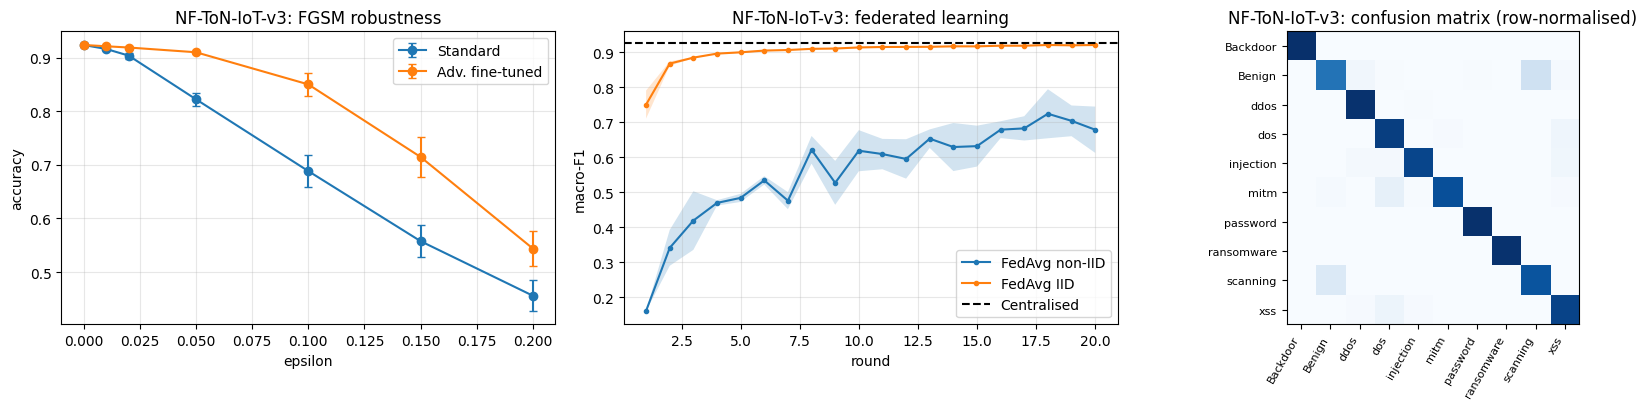

In [ ]:
# ===== Cell 11: figures =====
import matplotlib.pyplot as plt
for ds in df.dataset.unique():
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    # adversarial curve
    for mdl, lab in [("standard", "Standard"), ("adv_finetuned", "Adv. fine-tuned")]:
        g = dadv[(dadv.dataset == ds) & (dadv.model == mdl) & (dadv.attack == "fgsm")].groupby("eps")["accuracy"]
        ax[0].errorbar(g.mean().index, g.mean().values, yerr=g.std().fillna(0).values, marker="o", capsize=3, label=lab)
    ax[0].set(title=f"{ds}: FGSM robustness", xlabel="epsilon", ylabel="accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    # federated curve
    for part, lab in [("noniid", "FedAvg non-IID"), ("iid", "FedAvg IID")]:
        g = dfed[(dfed.dataset == ds) & (dfed.partition == part)].groupby("round")["macro_f1"]
        ax[1].plot(g.mean().index, g.mean().values, marker=".", label=lab)
        ax[1].fill_between(g.mean().index, (g.mean()-g.std().fillna(0)).values, (g.mean()+g.std().fillna(0)).values, alpha=.2)
    cen = df[(df.dataset == ds) & (df.method == "DeepGuard (cWGAN-GP)")].macro_f1.mean()
    ax[1].axhline(cen, color="k", ls="--", label="Centralised"); ax[1].set(title=f"{ds}: federated learning", xlabel="round", ylabel="macro-F1"); ax[1].legend(); ax[1].grid(alpha=.3)
    # confusion matrix (first seed)
    d = json.load(open(os.path.join(OUT, f"{ds}_seed{SEEDS[0]}.json")))
    cm = confusion_matrix(DATA[ds]["yte"], d["preds"]["DeepGuard (cWGAN-GP)"], labels=range(len(DATA[ds]["classes"])))
    cm = cm / cm.sum(1, keepdims=True).clip(1)
    ax[2].imshow(cm, cmap="Blues"); ax[2].set_xticks(range(len(cm))); ax[2].set_yticks(range(len(cm)))
    ax[2].set_xticklabels(DATA[ds]["classes"], rotation=60, ha="right", fontsize=8); ax[2].set_yticklabels(DATA[ds]["classes"], fontsize=8)
    ax[2].set(title=f"{ds}: confusion matrix (row-normalised)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f"fig_{ds}.png"), dpi=200); plt.show()

  0%|          | 0/120 [00:00<?, ?it/s]


NF-ToN-IoT-v3 top-10 SHAP features:
 L4_DST_PORT          0.023258
L7_PROTO             0.013613
PROTOCOL             0.013332
IN_PKTS              0.011549
IN_BYTES             0.011149
SHORTEST_FLOW_PKT    0.009954
TCP_WIN_MAX_IN       0.008402
L4_SRC_PORT          0.006701
MIN_TTL              0.006002
TCP_WIN_MAX_OUT      0.005965
dtype: float64


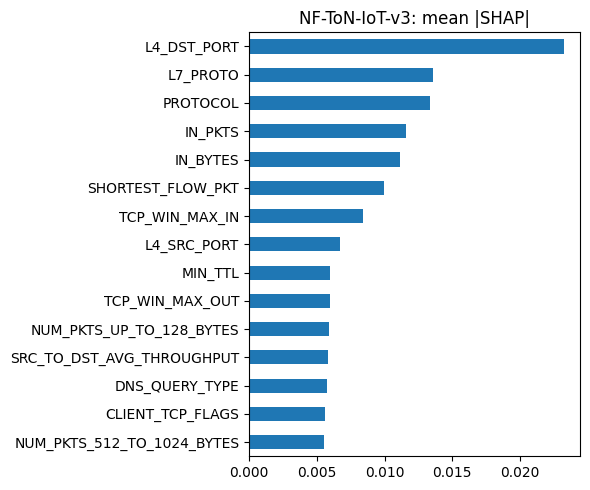

In [ ]:
# ===== Cell 12: SHAP (KernelSHAP, 40 background, 120 test instances, 100 coalitions – as in the paper) =====
import shap
def run_shap(name, D, seed):
    C = len(D["classes"]); m = DeepGuard(C).to(DEVICE)
    m.load_state_dict(torch.load(os.path.join(OUT, f"{name}_seed{seed}_main.pt"))); m.eval()
    rng = np.random.RandomState(0)
    bg = D["Xtr"][rng.choice(len(D["Xtr"]), 40, replace=False)]
    Xs = D["Xte"][rng.choice(len(D["Xte"]), 120, replace=False)]
    f = lambda a: predict_proba(m, torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE))
    sv = shap.KernelExplainer(f, bg).shap_values(Xs, nsamples=100)
    if isinstance(sv, list): imp = np.mean([np.abs(s) for s in sv], axis=0)
    else:
        imp = np.abs(sv); imp = imp.mean(-1) if imp.ndim == 3 else imp
    imp = imp.mean(0)
    s = pd.Series(imp, index=D["features"]).sort_values(ascending=False)
    s.to_csv(os.path.join(OUT, f"shap_{name}.csv")); print(f"\n{name} top-10 SHAP features:\n", s.head(10))
    s.head(15)[::-1].plot.barh(figsize=(6, 5), title=f"{name}: mean |SHAP|"); plt.tight_layout()
    plt.savefig(os.path.join(OUT, f"fig_shap_{name}.png"), dpi=200); plt.show()

if RUN_SHAP:
    for name, D in DATA.items(): run_shap(name, D, SEEDS[0])

In [ ]:
import sys, torch, sklearn, imblearn, shap, numpy, pandas
print("Python", sys.version.split()[0])
print("torch", torch.__version__, "| sklearn", sklearn.__version__, "| imblearn", imblearn.__version__,
      "| shap", shap.__version__, "| numpy", numpy.__version__, "| pandas", pandas.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Python 3.13.15
torch 2.11.0+cu130 | sklearn 1.6.1 | imblearn 0.14.2 | shap 0.54.1 | numpy 2.1.3 | pandas 2.2.3
GPU: Tesla T4


Binary view (benign = negative):
                  tpr             fpr        
                 mean     std    mean     std
dataset                                      
NF-ToN-IoT-v3  0.9833  0.0004  0.2582  0.0054

Per-class one-vs-rest TPR (recall) and FPR, mean over seeds:
                             tpr     fpr
dataset       cls                       
NF-ToN-IoT-v3 Backdoor    0.9990  0.0001
              Benign      0.7418  0.0167
              ddos        0.9813  0.0075
              dos         0.9623  0.0176
              injection   0.9171  0.0034
              mitm        0.8747  0.0014
              password    0.9942  0.0012
              ransomware  0.9901  0.0002
              scanning    0.8626  0.0261
              xss         0.9109  0.0121


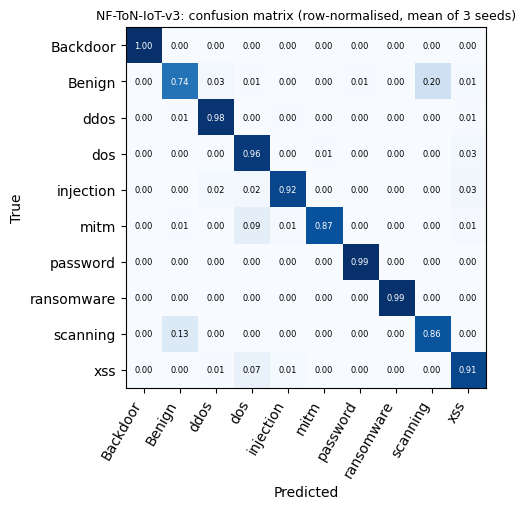

In [ ]:
SEEDS = [42, 43, 44, 45, 46]    # missing seeds are skipped automatically
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
rows, cms = [], []
for name, D in DATA.items():
    classes = D["classes"]; C = len(classes)
    neg = classes.index("Normal" if "Normal" in classes else "Benign")
    Xte_t = torch.tensor(D["Xte"], device=DEVICE); yte = D["yte"]
    cm_sum = np.zeros((C, C)); used = 0
    for seed in SEEDS:
        path = os.path.join(OUT, f"{name}_seed{seed}_main.pt")
        if not os.path.exists(path): continue
        m = DeepGuard(C).to(DEVICE); m.load_state_dict(torch.load(path, map_location=DEVICE)); m.eval()
        pred = predict_proba(m, Xte_t).argmax(1)
        cm = confusion_matrix(yte, pred, labels=list(range(C))); cm_sum += cm; used += 1
        neg_mask = (yte == neg)
        rows.append(dict(dataset=name, seed=seed, cls="BINARY (benign vs any attack)",
                         tpr=float((pred[~neg_mask] != neg).mean()),
                         fpr=float((pred[neg_mask] != neg).mean())))
        for c in range(C):
            tp = cm[c, c]; fp = cm[:, c].sum() - tp; tn = cm.sum() - cm[c, :].sum() - cm[:, c].sum() + tp
            rows.append(dict(dataset=name, seed=seed, cls=classes[c], tpr=float(tp / cm[c, :].sum()), fpr=float(fp / (fp + tn))))
    if used: cms.append((name, classes, cm_sum, used))
res = pd.DataFrame(rows)
print("Binary view (benign = negative):")
print(res[res.cls.str.startswith("BINARY")].groupby("dataset")[["tpr", "fpr"]].agg(["mean", "std"]).round(4))
print("\nPer-class one-vs-rest TPR (recall) and FPR, mean over seeds:")
print(res[~res.cls.str.startswith("BINARY")].groupby(["dataset", "cls"])[["tpr", "fpr"]].mean().round(4))
res.to_csv(os.path.join(OUT, "fpr_per_class.csv"), index=False)
for name, classes, cm, used in cms:
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=60, ha="right"); ax.set_yticklabels(classes)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"{name}: confusion matrix (row-normalised, mean of {used} seeds)", fontsize=9)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f"confusion_{name}.png"), dpi=200); plt.show()

In [ ]:
# ===== Cell 14: class-weighted and tuned classical baselines (CPU only; resumable) =====
# Paste as a NEW cell at the end of EITHER notebook (NSL-KDD/UNSW notebook or NF-ToN-IoT notebook).
# Run Cells 1-4 first (imports, config, data loading, helpers). No GPU is needed: Runtime -> CPU is fine.
# It needs DATA, SEEDS, OUT and evaluate() from the notebook, and the per-seed *_seed*.json files in OUT.
# Results of each dataset are saved to OUT as soon as that dataset finishes; with RESUME = True a finished
# dataset is skipped, so a disconnect does not lose it. Use ONLY to run one dataset per cell run.
import itertools, json, os, time, warnings
import numpy as np, pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
warnings.filterwarnings("ignore")

ONLY = None                      # e.g. ["UNSW-NB15"] to run a single dataset; None = all datasets in DATA
RESUME = True                    # skip datasets already present in strong_baselines_raw.csv
SEEDS_DS = {"NSL-KDD+": [42, 43, 44, 45, 46]}          # seeds per dataset (others use SEEDS from the notebook)
TUNE_FRAC = {"Linear SVM (tuned)": 0.25}               # the SVM is tuned on a stratified 25% of the tuning set (speed)
RAW_CSV = os.path.join(OUT, "strong_baselines_raw.csv")

# 1) class-weighted but otherwise the paper's settings (untuned)
FIXED = {
    "Random Forest (balanced)":       lambda seed: RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1,
                                                    class_weight="balanced_subsample", random_state=seed),
    "Logistic Regression (balanced)": lambda seed: LogisticRegression(max_iter=300, class_weight="balanced"),
    "Linear SVM (balanced)":          lambda seed: LinearSVC(max_iter=2000, class_weight="balanced", random_state=seed),
}
# 2) small grids; class weighting is part of the grid. Selection by macro-F1 on a validation set.
GRIDS = {
    "Random Forest (tuned)": (lambda **k: RandomForestClassifier(n_estimators=100, n_jobs=-1, **k),
        dict(max_depth=[10, 20, None], min_samples_leaf=[1, 3], class_weight=[None, "balanced_subsample"])),
    "Logistic Regression (tuned)": (lambda **k: LogisticRegression(max_iter=500, **k),
        dict(C=[0.1, 1, 10], class_weight=[None, "balanced"])),
    "Linear SVM (tuned)": (lambda **k: LinearSVC(max_iter=1000, **k),
        dict(C=[0.1, 1], class_weight=[None, "balanced"])),
    "HistGradientBoosting (tuned)": (lambda **k: HistGradientBoostingClassifier(max_iter=300, early_stopping=True, **k),
        dict(max_leaf_nodes=[31, 63], class_weight=[None, "balanced"])),
}
DETERMINISTIC = ("Logistic Regression", "Linear SVM")  # fitted once, result reused for every seed

def _scores(m, X):
    return m.predict_proba(X) if hasattr(m, "predict_proba") else m.decision_function(X)

def _val_split(D):
    if "Xva" in D: return D["Xtr"], D["ytr"], D["Xva"], D["yva"]            # NF-ToN-IoT-v3 has a validation split
    Xa, Xv, ya, yv = train_test_split(D["Xtr"], D["ytr"], test_size=0.2, stratify=D["ytr"], random_state=42)
    return Xa, ya, Xv, yv                                                    # NSL-KDD+/UNSW-NB15: 80/20 of TRAIN only

def tune(name, D, C):
    make, grid = GRIDS[name]; Xa, ya, Xv, yv = _val_split(D); best = (-1.0, None); t0 = time.time()
    frac = TUNE_FRAC.get(name, 1.0)
    if frac < 1.0: Xa, _, ya, _ = train_test_split(Xa, ya, train_size=frac, stratify=ya, random_state=42)
    for vals in itertools.product(*grid.values()):
        kw = dict(zip(grid.keys(), vals)); m = make(**kw).set_params(random_state=42).fit(Xa, ya)
        f = f1_score(yv, _scores(m, Xv).argmax(1), average="macro", labels=list(range(C)), zero_division=0)
        if f > best[0]: best = (f, kw)
    print(f"  tuned {name}: {best[1]}  validation macro-F1 = {best[0]:.4f}  ({time.time() - t0:.0f}s)", flush=True)
    return best[1]

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.zeros(len(p)); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

old = pd.read_csv(RAW_CSV) if (RESUME and os.path.exists(RAW_CSV)) else pd.DataFrame()
done = set(old.dataset.unique()) if len(old) else set()
rows = old.to_dict("records")
for name, D in DATA.items():
    if (ONLY is not None and name not in ONLY) or name in done:
        print(f"skip {name} ({'finished earlier' if name in done else 'not selected'})"); continue
    C, classes = len(D["classes"]), list(D["classes"]); Xtr, ytr, Xte, yte = D["Xtr"], D["ytr"], D["Xte"], D["yte"]
    nid = [i for i, c in enumerate(classes) if str(c).lower() in ("normal", "benign")][0]
    print(f"\n=== {name}: tuning on a validation set, then fitting on the training set ===", flush=True)
    best = {n: tune(n, D, C) for n in GRIDS}
    cache = {}; new_rows = []
    for seed in SEEDS_DS.get(name, SEEDS):
        models = {n: make(**best[n]).set_params(random_state=seed) for n, (make, _) in GRIDS.items()}
        models.update({n: f(seed) for n, f in FIXED.items()})
        for n, m in models.items():
            if n.startswith(DETERMINISTIC) and n in cache:
                r = dict(cache[n]); r["seed"] = seed; new_rows.append(r); continue
            t0 = time.time(); m.fit(Xtr, ytr); S = _scores(m, Xte); pred = S.argmax(1)
            r = evaluate(yte, pred, S, C); pcr = r.pop("per_class_recall")
            for k in ("per_class_precision", "per_class_f1"): r.pop(k)
            att = yte != nid
            r.update(dataset=name, seed=seed, method=n, detection_rate=float((pred[att] != nid).mean()),
                     false_alarm_rate=float((pred[~att] != nid).mean()), **{f"recall_{c}": v for c, v in zip(classes, pcr)})
            new_rows.append(r)
            if n.startswith(DETERMINISTIC): cache[n] = dict(r)
            print(f"  seed {seed} {n:30s} acc={r['accuracy']:.4f} macroF1={r['macro_f1']:.4f} FA={r['false_alarm_rate']:.3f} ({time.time() - t0:.0f}s)", flush=True)
    rows += new_rows; pd.DataFrame(rows).to_csv(RAW_CSV, index=False)      # saved as soon as this dataset is done
    print(f"saved {name} to {RAW_CSV}", flush=True)

raw = pd.DataFrame(rows)
def sd(x): return x.std(ddof=1)
summ = raw.groupby(["dataset", "method"])[["accuracy", "macro_f1", "mcc", "macro_auc", "detection_rate", "false_alarm_rate"]].agg(["mean", sd])
summ.to_csv(os.path.join(OUT, "strong_baselines_summary.csv")); print("\n=== mean and std over seeds ==="); display(summ.round(4))

# paired comparison with DeepGuard (same seeds, macro-F1); Holm over the new baselines within dataset and DeepGuard variant
def dg_f1(name, method):
    out = {}
    for s in SEEDS_DS.get(name, SEEDS):
        f = os.path.join(OUT, f"{name}_seed{s}.json")
        if os.path.exists(f):
            for r in json.load(open(f))["main"]:
                if r["method"] == method: out[s] = r["macro_f1"]
    return out

cmp_rows = []
for name in raw.dataset.unique():
    for dg in ["DeepGuard (no aug)", "DeepGuard (cWGAN-GP)"]:
        a = dg_f1(name, dg); block = []
        for n in raw[raw.dataset == name].method.unique():
            b = raw[(raw.dataset == name) & (raw.method == n)].set_index("seed").macro_f1.to_dict()
            seeds = sorted(set(a) & set(b))
            if len(seeds) < 3: continue
            x = np.array([a[s] for s in seeds]); y = np.array([b[s] for s in seeds]); d = x - y
            t = stats.t.ppf(0.975, len(d) - 1); h = t * d.std(ddof=1) / np.sqrt(len(d))
            block.append(dict(dataset=name, deepguard=dg, baseline=n, n_seeds=len(d), mean_diff=d.mean(), ci_low=d.mean() - h,
                              ci_high=d.mean() + h, d_z=d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.nan,
                              p=stats.ttest_rel(x, y).pvalue))
        if block:
            for r, pa in zip(block, holm([r["p"] for r in block])): r["p_holm"] = pa
            cmp_rows += block
cmp_df = pd.DataFrame(cmp_rows); cmp_df.to_csv(os.path.join(OUT, "strong_baselines_vs_deepguard.csv"), index=False)
print("\n=== DeepGuard minus baseline (macro-F1, paired over seeds) ==="); display(cmp_df.round(4))

skip NF-ToN-IoT-v3 (finished earlier)

=== mean and std over seeds ===


accuracy         macro_f1             mcc         macro_auc         detection_rate         false_alarm_rate        
                                                 mean      sd     mean      sd    mean      sd      mean      sd           mean      sd             mean      sd
dataset       method                                                                                                                                            
NF-ToN-IoT-v3 HistGradientBoosting (tuned)     0.9320  0.0005   0.9360  0.0006  0.9231  0.0006    0.9958  0.0005         0.9825  0.0005           0.2352  0.0026
              Linear SVM (balanced)            0.8505  0.0000   0.8329  0.0000  0.8335  0.0000    0.9805  0.0000         0.9867  0.0000           0.5591  0.0000
              Linear SVM (tuned)               0.8540  0.0000   0.8437  0.0000  0.8367  0.0000    0.9798  0.0000         0.9842  0.0000           0.5287  0.0000
              Logistic Regression (balanced)   0.8699  0.0000   0.8516  0.0000  0.8554  0.0000    0.9864  0.0000         0.9910  0.0000           0.5427  0.0000
              Logistic Regression (tuned)      0.8763  0.0000   0.8658  0.0000  0.8620  0.0000    0.9865  0.0000         0.9884  0.0000           0.5287  0.0000
              Random Forest (balanced)         0.9305  0.0003   0.9336  0.0004  0.9214  0.0003    0.9958  0.0000         0.9817  0.0002           0.2324  0.0016
              Random Forest (tuned)            0.9303  0.0002   0.9342  0.0002  0.9212  0.0002    0.9958  0.0000         0.9814  0.0001           0.2305  0.0017


=== DeepGuard minus baseline (macro-F1, paired over seeds) ===


,dataset,deepguard,baseline,n_seeds,mean_diff,ci_low,ci_high,d_z,p,p_holm
0,NF-ToN-IoT-v3,DeepGuard (no aug),Random Forest (tuned),3,-0.0094,-0.0124,-0.0064,-7.7417,0.0055,0.0108
1,NF-ToN-IoT-v3,DeepGuard (no aug),Logistic Regression (tuned),3,0.0591,0.0562,0.0619,51.6245,0.0001,0.0005
2,NF-ToN-IoT-v3,DeepGuard (no aug),Linear SVM (tuned),3,0.0812,0.0783,0.0840,70.9456,0.0001,0.0004
3,NF-ToN-IoT-v3,DeepGuard (no aug),HistGradientBoosting (tuned),3,-0.0113,-0.0149,-0.0077,-7.8148,0.0054,0.0108
4,NF-ToN-IoT-v3,DeepGuard (no aug),Random Forest (balanced),3,-0.0089,-0.0107,-0.0070,-11.9084,0.0023,0.0070
5,NF-ToN-IoT-v3,DeepGuard (no aug),Logistic Regression (balanced),3,0.0732,0.0703,0.0760,63.9808,0.0001,0.0004
6,NF-ToN-IoT-v3,DeepGuard (no aug),Linear SVM (balanced),3,0.0919,0.0891,0.0947,80.3325,0.0001,0.0004
7,NF-ToN-IoT-v3,DeepGuard (cWGAN-GP),Random Forest (tuned),3,-0.0095,-0.0122,-0.0068,-8.7720,0.0043,0.0129
8,NF-ToN-IoT-v3,DeepGuard (cWGAN-GP),Logistic Regression (tuned),3,0.0589,0.0560,0.0618,50.9049,0.0001,0.0005
9,NF-ToN-IoT-v3,DeepGuard (cWGAN-GP),Linear SVM (tuned),3,0.0810,0.0781,0.0839,70.0039,0.0001,0.0004


In [ ]:
D = DATA["NF-ToN-IoT-v3"]
for n in GRIDS: tune(n, D, len(D["classes"]))

  tuned Random Forest (tuned): {'max_depth': 20, 'min_samples_leaf': 1, 'class_weight': None}  validation macro-F1 = 0.9344  (266s)
  tuned Logistic Regression (tuned): {'C': 10, 'class_weight': None}  validation macro-F1 = 0.8626  (415s)
  tuned Linear SVM (tuned): {'C': 1, 'class_weight': None}  validation macro-F1 = 0.8394  (50s)
  tuned HistGradientBoosting (tuned): {'max_leaf_nodes': 63, 'class_weight': None}  validation macro-F1 = 0.9372  (176s)


In [ ]:
class DGAblation(nn.Module):
    def __init__(self, C, cnn=True, lstm=True, attn=True):
        super().__init__()
        self.cnn, self.lstm_on, self.attn_on = cnn, lstm, attn
        if cnn:
            self.c1 = nn.Conv1d(1, 16, 3, padding=1)
            self.c2 = nn.Conv1d(16, 32, 3, padding=2, dilation=2); self.b2 = nn.BatchNorm1d(32)
            self.c3 = nn.Conv1d(32, 64, 3, padding=2, dilation=2); self.b3 = nn.BatchNorm1d(64)
            self.proj = nn.Conv1d(16, 64, 1)
        d_in = 64 if cnn else 1
        if lstm:
            self.lstm = nn.LSTM(d_in, 24, batch_first=True, bidirectional=True); d = 48
        else:
            d = d_in
        if attn:
            self.attn = nn.MultiheadAttention(d, 4 if d % 4 == 0 else 1, batch_first=True); self.ln = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 64); self.drop = nn.Dropout(0.3); self.fc2 = nn.Linear(64, C)
    def forward(self, x):
        x = x.unsqueeze(1)
        if self.cnn:
            h1 = F.relu(self.c1(x)); h2 = F.relu(self.b2(self.c2(h1)))
            h = F.relu(self.b3(self.c3(h2) + self.proj(h1))).transpose(1, 2)
        else:
            h = x.transpose(1, 2)
        if self.lstm_on: h, _ = self.lstm(h)
        if self.attn_on:
            a, _ = self.attn(h, h, h); h = self.ln(h + a)
        return self.fc2(self.drop(F.relu(self.fc1(h.mean(1)))))

VARIANTS = {"full": (True, True, True), "no attention": (True, True, False),
            "no BiLSTM": (True, False, True), "no CNN": (False, True, True)}
rows = []
for name, D in DATA.items():
    if name.startswith("UNSW"): continue
    C = len(D["classes"]); w = class_weights(D["ytr"], C)
    Xtr_t = torch.tensor(D["Xtr"], device=DEVICE); ytr_t = torch.tensor(D["ytr"], device=DEVICE)
    Xte_t = torch.tensor(D["Xte"], device=DEVICE)
    kw = dict(val=(torch.tensor(D["Xva"], device=DEVICE), D["yva"])) if "Xva" in D else {}
    for seed in SEEDS:
        for vname, (a, b, c) in VARIANTS.items():
            set_seed(seed)
            m = DGAblation(C, a, b, c).to(DEVICE)
            train_model(m, Xtr_t, ytr_t, EPOCHS, w=w, tag=vname, verbose=False, **kw)
            pred = predict_proba(m, Xte_t).argmax(1)
            rows.append(dict(dataset=name, seed=seed, variant=vname, params=sum(p.numel() for p in m.parameters()),
                             accuracy=float(accuracy_score(D["yte"], pred)),
                             macro_f1=float(f1_score(D["yte"], pred, average="macro", labels=list(range(C)), zero_division=0))))
        print("done", name, seed)
abl = pd.DataFrame(rows)
print(abl.groupby(["dataset", "variant"])[["params", "accuracy", "macro_f1"]].agg(["mean", "std"]).round(4))
abl.to_csv(os.path.join(OUT, "architecture_ablation.csv"), index=False)

done NF-ToN-IoT-v3 42
done NF-ToN-IoT-v3 43
done NF-ToN-IoT-v3 44
done NF-ToN-IoT-v3 45
done NF-ToN-IoT-v3 46
                             params      accuracy         macro_f1        
                               mean  std     mean     std     mean     std
dataset       variant                                                     
NF-ToN-IoT-v3 full          39690.0  0.0   0.9233  0.0010   0.9245  0.0012
              no BiLSTM     30698.0  0.0   0.9229  0.0005   0.9237  0.0012
              no CNN        18474.0  0.0   0.9095  0.0028   0.9034  0.0033
              no attention  30186.0  0.0   0.9219  0.0006   0.9228  0.0012
